# ACA N.° 1 – Computación en la Nube
## Ingesta, vectorización y almacenamiento vectorial en la nube para un sistema RAG sobre cáncer de mama
**Pilar:** Salud · **Dataset base:** UCI Breast Cancer Wisconsin (Diagnostic) (Wolberg et al., 1995)
**Autor:** Cristian Fernando Marín Caro · **Docente:** Hamilton Rivera Flor · CUN – Especialización en Inteligencia Artificial

**Pregunta orientadora:** ¿cómo estructurar e implementar una canalización de datos no estructurados en la nube, con una base de datos vectorial serverless y modelos de embeddings, que permita recuperar semánticamente información clínica especializada con alta precisión, costo cero y baja latencia?

### Arquitectura implementada
```
 Documentos clínicos (PDF/TXT)      Dataset estructurado (UCI WDBC)
            │                                   │
            ▼                                   ▼
   Extracción y limpieza              Fichas textuales con metadatos
            └────────────┬──────────────────────┘
                         ▼
        Chunking (RecursiveCharacterTextSplitter)
                         ▼
   Embeddings (Google Gemini, RETRIEVAL_DOCUMENT, 768 dim.)
                         ▼
   Batch upsert ─►  Qdrant Cloud (distancia coseno)  ◄─ consulta vectorizada (RETRIEVAL_QUERY)
                         ▼
              Top-k fragmentos + similitud coseno


## 0. Preparación del entorno

In [1]:
!pip -q install qdrant-client google-genai pypdf python-dotenv langchain-text-splitters tqdm

In [2]:
import os, re, json, time, uuid, unicodedata, getpass, textwrap
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from dotenv import load_dotenv
from pypdf import PdfReader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from google import genai
from google.genai import types
from qdrant_client import QdrantClient
from qdrant_client.models import (VectorParams, Distance, PointStruct, PayloadSchemaType,
                                 Filter, FieldCondition, MatchValue)
pd.set_option("display.max_colwidth", 120)

### Parámetros del proyecto
* **Modelo de embeddings:** `gemini-embedding-2` (modelo vigente de la API de Gemini; la guía exige Gemini Embeddings 2).
* **Dimensión 768:** el modelo admite 768, 1536 o 3072. 768 conserva buena calidad y reduce cuatro veces el almacenamiento frente a 3072, lo que cuida la capa gratuita de Qdrant (1 GB).
* **Distancia coseno:** compara la dirección de los vectores y no su magnitud, que es lo adecuado para similitud semántica de texto.
* **Chunking de 1000 caracteres con 150 de solapamiento:** se justifica con datos en la sección 3.

In [3]:
COLLECTION = "rag_cancer_mama"
EMBED_MODEL = "gemini-embedding-2"
DIM = 768
CHUNK_SIZE = 1000
CHUNK_OVERLAP = 150
BATCH_SIZE = 32
RESET_COLLECTION = True
MODO_TAREA = "task_type"
EVALUAR_TAMANOS = False
CORPUS_DIR = Path("corpus"); CORPUS_DIR.mkdir(exist_ok=True)

### Credenciales seguras (variables de entorno)
Las claves se leen desde `.env`. Si no existe, el notebook intenta los *Secrets* de Colab y, en último caso, las solicita de forma oculta. Las claves nunca se imprimen.

In [4]:
if not any(Path(f).exists() for f in (".env", "env.txt")):
    try:
        from google.colab import files
        print("Sube tu archivo .env (o cancela para escribir las claves manualmente).")
        files.upload()
    except Exception:
        pass
for f in (".env", "env.txt"):
    if Path(f).exists():
        load_dotenv(f)

def credencial(nombre):
    valor = os.getenv(nombre)
    if not valor:
        try:
            from google.colab import userdata
            valor = userdata.get(nombre)
        except Exception:
            valor = None
    if not valor:
        valor = getpass.getpass(f"{nombre}: ")
    os.environ[nombre] = valor
    return valor

QDRANT_URL = credencial("QDRANT_URL")
QDRANT_API_KEY = credencial("QDRANT_API_KEY")
GOOGLE_API_KEY = credencial("GOOGLE_API_KEY")
print("✅ Credenciales cargadas:", {k: "***" + os.environ[k][-4:] for k in ("QDRANT_API_KEY", "GOOGLE_API_KEY")})

Sube tu archivo .env (o cancela para escribir las claves manualmente).


Saving env.txt to env.txt
✅ Credenciales cargadas: {'QDRANT_API_KEY': '***L7bM', 'GOOGLE_API_KEY': '***GgSg'}


## 1. Aprovisionamiento de la base de datos vectorial en la nube

In [5]:
cliente_q = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY, timeout=60)
cliente_g = genai.Client(api_key=GOOGLE_API_KEY)
print("Conexión a Qdrant Cloud OK. Colecciones existentes:", [c.name for c in cliente_q.get_collections().collections])

Conexión a Qdrant Cloud OK. Colecciones existentes: []


In [6]:
def preparar_coleccion(cliente, nombre, reset=False):
    if cliente.collection_exists(nombre) and reset:
        cliente.delete_collection(nombre)
    if not cliente.collection_exists(nombre):
        cliente.create_collection(
            collection_name=nombre,
            vectors_config=VectorParams(size=DIM, distance=Distance.COSINE))

    for campo in ("tipo", "fuente", "pilar"):
        cliente.create_payload_index(nombre, field_name=campo, field_schema=PayloadSchemaType.KEYWORD)

preparar_coleccion(cliente_q, COLLECTION, RESET_COLLECTION)
info = cliente_q.get_collection(COLLECTION)
print(f"Colección '{COLLECTION}' lista · dimensión {DIM} · distancia coseno · puntos: {info.points_count}")

Colección 'rag_cancer_mama' lista · dimensión 768 · distancia coseno · puntos: 0


## 2. Documentos e ingesta
El corpus complementario está formado por documentos clínicos reales del sector salud, más la documentación del propio dataset:

| Archivo sugerido | Documento | Entidad |
|---|---|---|
| `01_GPC_pacientes_MinSalud_2013.pdf` | GPC para la detección temprana, tratamiento integral, seguimiento y rehabilitación del cáncer de mama – versión para pacientes y cuidadores (GPC-2013-19) | MinSalud, Colciencias, INC (Colombia) |
| `02_OMS_cancer_de_mama.pdf` | Cáncer de mama – nota descriptiva | Organización Mundial de la Salud |
| `03_Guia_clinica_cancer_mama_2020.pdf` | Guía clínica de oncología: diagnóstico y manejo del cáncer de mama | Universidad Sanitas |
| `wdbc.names` | Documentación oficial del dataset | UCI ML Repository |

In [7]:
if not any(p.suffix.lower() in {".pdf", ".txt", ".md", ".names"} for p in CORPUS_DIR.glob("*")):
    try:
        from google.colab import files
        print("Sube los documentos del corpus (PDF/TXT/MD) y, si los tienes, wdbc.data y wdbc.names")
        for nombre, contenido in files.upload().items():
            (CORPUS_DIR / nombre).write_bytes(contenido)
    except Exception:
        print("Copia tus documentos manualmente en la carpeta corpus/")
print(sorted(p.name for p in CORPUS_DIR.glob("*")))

Sube los documentos del corpus (PDF/TXT/MD) y, si los tienes, wdbc.data y wdbc.names


Saving 01_GPC_pacientes_MinSalud_2013.pdf to 01_GPC_pacientes_MinSalud_2013.pdf
Saving 02_OMS_cancer_de_mama.pdf to 02_OMS_cancer_de_mama.pdf
Saving 03_Guia_clinica_cancer_mama_2020.pdf to 03_Guia_clinica_cancer_mama_2020.pdf
Saving wdbc.data to wdbc.data
Saving wdbc.names to wdbc.names
['01_GPC_pacientes_MinSalud_2013.pdf', '02_OMS_cancer_de_mama.pdf', '03_Guia_clinica_cancer_mama_2020.pdf', 'wdbc.data', 'wdbc.names']


In [8]:

REGISTRO = {
    "01_":  dict(titulo="GPC cáncer de mama – versión para pacientes y cuidadores", entidad="MinSalud / Colciencias / INC", anio=2013, tipo="guia_pacientes"),
    "02_":  dict(titulo="Cáncer de mama – nota descriptiva OMS", entidad="Organización Mundial de la Salud", anio=None, tipo="nota_oms"),
    "03_":  dict(titulo="Guía clínica: diagnóstico y manejo del cáncer de mama", entidad="Universidad Sanitas", anio=2020, tipo="guia_profesional"),
    "wdbc": dict(titulo="Documentación del dataset UCI WDBC", entidad="UCI ML Repository", anio=1995, tipo="diccionario_dataset"),
}

def limpiar(texto):
    texto = unicodedata.normalize("NFKC", texto)
    texto = texto.replace("\u00ad", "")
    texto = re.sub(r"-\n(?=[a-záéíóúñ])", "", texto)
    texto = re.sub(r"[ \t]+", " ", texto)
    texto = re.sub(r"\n{3,}", "\n\n", texto)
    return texto.strip()

def cargar_documentos(carpeta):
    paginas = []
    for ruta in sorted(carpeta.glob("*")):
        if ruta.suffix.lower() not in {".pdf", ".txt", ".md", ".names"}:
            continue
        meta = next((m for k, m in REGISTRO.items() if ruta.name.lower().startswith(k)),
                    dict(titulo=ruta.stem, entidad="N/D", anio=None, tipo="documento"))
        if ruta.suffix.lower() == ".pdf":
            for n, pag in enumerate(PdfReader(str(ruta)).pages, start=1):
                t = limpiar(pag.extract_text() or "")
                if len(t) > 50:
                    paginas.append(dict(texto=t, fuente=ruta.name, pagina=n, **meta))
        else:
            t = limpiar(ruta.read_text(encoding="utf-8", errors="ignore"))
            paginas.append(dict(texto=t, fuente=ruta.name, pagina=1, **meta))
    return paginas

paginas = cargar_documentos(CORPUS_DIR)
resumen = (pd.DataFrame(paginas).groupby(["fuente", "tipo"])
           .agg(paginas=("pagina", "count"), caracteres=("texto", lambda s: s.str.len().sum()),
                palabras=("texto", lambda s: s.str.split().str.len().sum())).reset_index())
display(resumen)
assert len(resumen) >= 2, "El corpus debe tener al menos 2 documentos."

,fuente,tipo,paginas,caracteres,palabras
0,01_GPC_pacientes_MinSalud_2013.pdf,guia_pacientes,23,37473,6037
1,02_OMS_cancer_de_mama.pdf,nota_oms,7,15213,2407
2,03_Guia_clinica_cancer_mama_2020.pdf,guia_profesional,31,46762,7118
3,wdbc.names,diccionario_dataset,1,4691,645


### Dataset estructurado como fuente de metadatos
Los 569 registros del conjunto de datos UCI WDBC se organizaron en fichas de texto: una general y otras para cada característica celular. Cada ficha incluye información adicional, como los valores promedio de los tumores benignos y malignos y la diferencia porcentual entre ellos.

De esta manera, fue posible integrar los datos del dataset con los documentos clínicos en una misma base vectorial, facilitando su consulta mediante preguntas en lenguaje natural o filtros según el tipo de información. También se agregó una ficha con los resultados del modelo SVM desarrollado en el proyecto de Aprendizaje Automático.

In [9]:
BASES = ["radius", "texture", "perimeter", "area", "smoothness", "compactness", "concavity",
         "concave points", "symmetry", "fractal dimension"]
ES = {"radius": "radio", "texture": "textura", "perimeter": "perímetro", "area": "área", "smoothness": "suavidad",
      "compactness": "compacidad", "concavity": "concavidad", "concave points": "puntos cóncavos",
      "symmetry": "simetría", "fractal dimension": "dimensión fractal"}

def cargar_wdbc():
    for ruta in (CORPUS_DIR / "wdbc.data", Path("wdbc.data")):
        if ruta.exists():
            nombres = (["id", "diagnostico"] + ["mean " + b for b in BASES]
                       + [b + " error" for b in BASES] + ["worst " + b for b in BASES])
            return pd.read_csv(ruta, header=None, names=nombres).drop(columns="id"), f"archivo original {ruta.name}"
    from sklearn.datasets import load_breast_cancer
    df = load_breast_cancer(as_frame=True).frame.copy()
    df["diagnostico"] = np.where(df["target"] == 0, "M", "B")
    return df.drop(columns="target"), "copia del mismo dataset incluida en scikit-learn"

df_wdbc, origen = cargar_wdbc()
print(f"UCI WDBC cargado desde: {origen} · {df_wdbc.shape[0]} casos · {df_wdbc.shape[1]-1} variables")
print(df_wdbc["diagnostico"].value_counts().to_dict())

UCI WDBC cargado desde: archivo original wdbc.data · 569 casos · 30 variables
{'B': 357, 'M': 212}


In [10]:
def construir_fichas(df):
    M, B = df[df.diagnostico == "M"], df[df.diagnostico == "B"]
    base = dict(fuente="wdbc.data", titulo="Dataset UCI Breast Cancer Wisconsin (Diagnostic)",
                entidad="UCI ML Repository", anio=1995, pagina=0)
    fichas = [(
        f"El dataset UCI Breast Cancer Wisconsin (Diagnostic) contiene {len(df)} casos de masas mamarias estudiadas mediante "
        f"aspirado con aguja fina: {len(B)} benignos y {len(M)} malignos. Cada caso se describe con 30 variables numéricas "
        "calculadas a partir de imágenes digitalizadas del núcleo celular: 10 características (radio, textura, perímetro, área, "
        "suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una como promedio (mean), "
        "error estándar (error) y peor valor (worst).", {**base, "tipo": "dataset", "variable": "general"})]
    for b in BASES:
        mM, mB = M[f"mean {b}"].mean(), B[f"mean {b}"].mean()
        dif = (mM - mB) / mB * 100
        sentido = "mayor" if dif > 0 else "menor"
        fichas.append((
            f"Característica celular «{ES[b]}» (variable {b}) del dataset UCI Breast Cancer Wisconsin. En los tumores malignos "
            f"su valor promedio es {mM:.4g}, frente a {mB:.4g} en los benignos: es {abs(dif):.1f} % {sentido} en los malignos. "
            f"Esta característica ayuda a distinguir tumores malignos de benignos a partir de la imagen del núcleo celular.",
            {**base, "tipo": "dataset", "variable": b, "media_maligno": round(float(mM), 5),
             "media_benigno": round(float(mB), 5), "diferencia_pct": round(float(dif), 1)}))
    fichas.append((
        "Resultados del modelo SVM entrenado sobre el dataset UCI WDBC en el proyecto de Aprendizaje Automático: en el conjunto "
        "de prueba de 114 pacientes alcanzó exactitud de 97,37 %, precision de 100 %, recall de 92,86 %, F1 de 96,30 % y "
        "ROC-AUC de 0,993. Detectó 39 de 42 tumores malignos y tuvo 3 falsos negativos y ningún falso positivo.",
        {**base, "tipo": "dataset_modelo", "variable": "svm_resultados"}))
    return fichas

fichas = construir_fichas(df_wdbc)
print(len(fichas), "fichas del dataset. Ejemplo:\n", fichas[1][0])

12 fichas del dataset. Ejemplo:
 Característica celular «radio» (variable radius) del dataset UCI Breast Cancer Wisconsin. En los tumores malignos su valor promedio es 17.46, frente a 12.15 en los benignos: es 43.8 % mayor en los malignos. Esta característica ayuda a distinguir tumores malignos de benignos a partir de la imagen del núcleo celular.


## 3. Pipeline de chunking
Se usa `RecursiveCharacterTextSplitter`, que intenta cortar primero por párrafos, luego por líneas y oraciones, y solo en último caso por palabras. Así los fragmentos conservan unidades de sentido completas.

In [11]:
def crear_splitter(size, overlap):
    return RecursiveCharacterTextSplitter(chunk_size=size, chunk_overlap=overlap,
                                          separators=["\n\n", "\n", ". ", "; ", " ", ""])

def construir_chunks(paginas, fichas, size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    splitter, chunks = crear_splitter(size, overlap), []
    for p in paginas:
        for i, trozo in enumerate(splitter.split_text(p["texto"])):
            payload = {k: p[k] for k in ("fuente", "titulo", "entidad", "anio", "tipo", "pagina")}
            payload.update(chunk_index=i, n_caracteres=len(trozo), pilar="salud", idioma="es", dataset_base="UCI WDBC")
            cid = str(uuid.uuid5(uuid.NAMESPACE_URL, f"{p['fuente']}|{p['pagina']}|{i}|{size}"))
            chunks.append(dict(id=cid, texto=trozo, payload=payload))
    for j, (texto, meta) in enumerate(fichas):
        payload = dict(meta, chunk_index=j, n_caracteres=len(texto), pilar="salud", idioma="es", dataset_base="UCI WDBC")
        chunks.append(dict(id=str(uuid.uuid5(uuid.NAMESPACE_URL, f"ficha|{meta['variable']}|{size}")),
                           texto=texto, payload=payload))
    return chunks

chunks = construir_chunks(paginas, fichas)
long = pd.Series([c["payload"]["n_caracteres"] for c in chunks])
print(f"Total de fragmentos: {len(chunks)} · longitud media {long.mean():.0f} car. · mediana {long.median():.0f} · máx. {long.max()}")
display(pd.DataFrame(chunks).assign(fuente=lambda d: d.payload.map(lambda p: p["fuente"])).groupby("fuente").size().rename("fragmentos").to_frame())

Total de fragmentos: 157 · longitud media 744 car. · mediana 915 · máx. 997


,fragmentos
fuente,
01_GPC_pacientes_MinSalud_2013.pdf,51
02_OMS_cancer_de_mama.pdf,21
03_Guia_clinica_cancer_mama_2020.pdf,67
wdbc.data,12
wdbc.names,6


### Justificación del tamaño de los fragmentos
Se comparan distintos tamaños con 15 % de solapamiento sobre el mismo corpus.

,tamano,solapamiento,fragmentos,longitud_media
0,400,60,336,332
1,700,105,210,560
2,1000,150,157,744
3,1500,225,118,982
4,2000,300,103,1122


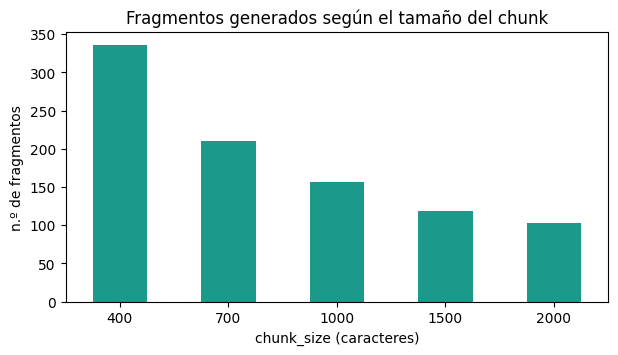

In [12]:
filas = []
for size in (400, 700, 1000, 1500, 2000):
    cs = construir_chunks(paginas, fichas, size, int(size * 0.15))
    l = pd.Series([c["payload"]["n_caracteres"] for c in cs])
    filas.append(dict(tamano=size, solapamiento=int(size * 0.15), fragmentos=len(cs), longitud_media=round(l.mean())))
tabla_chunks = pd.DataFrame(filas); display(tabla_chunks)
ax = tabla_chunks.plot(x="tamano", y="fragmentos", kind="bar", legend=False, color="#1b998b", rot=0, figsize=(7, 3.5))
ax.set(title="Fragmentos generados según el tamaño del chunk", xlabel="chunk_size (caracteres)", ylabel="n.º de fragmentos"); plt.show()

**Decisión: 1000 caracteres con 150 de solapamiento (15 %).**
* Se eligieron 1000 caracteres porque permiten conservar una buena cantidad de información sin mezclar demasiados temas dentro de un mismo fragmento.
* Los fragmentos de 400 caracteres podrían cortar algunas ideas o definiciones, además de generar más vectores y aumentar el consumo de recursos.
* El solapamiento de 150 caracteres ayuda a conservar la continuidad de la información entre un fragmento y otro, evitando perder detalles importantes.
* En el caso de los datos del dataset, la información es más corta, por lo que cada registro puede almacenarse en un solo fragmento.

## 4. Vectorización (embeddings) e indexación por lotes
Los documentos y las preguntas se procesan de manera diferente: los primeros utilizan RETRIEVAL_DOCUMENT y las consultas RETRIEVAL_QUERY. Esto permite que el sistema relacione mejor las preguntas con los documentos que contienen la información que se necesita.

Los vectores se ajustan para tener una longitud de 1, lo que facilita comparar su similitud y encontrar la información más relacionada.

La información se almacena por lotes, utilizando reintentos y tiempos de espera cuando se presentan límites de uso de la API. Esto ayuda a evitar errores y a aprovechar mejor los recursos disponibles en la versión gratuita.

In [13]:
def _formato(texto, tipo, titulo=None):
    if MODO_TAREA == "prefijo":
        return f"title: {titulo or 'none'} | text: {texto}" if tipo == "documento" else f"task: search result | query: {texto}"
    return texto

def _config(tipo):
    kw = {"output_dimensionality": DIM}
    if MODO_TAREA == "task_type":
        kw["task_type"] = "RETRIEVAL_DOCUMENT" if tipo == "documento" else "RETRIEVAL_QUERY"
    return types.EmbedContentConfig(**kw)

def _normalizar(v):
    v = np.asarray(v, dtype=np.float32); n = np.linalg.norm(v)
    return v / n if n else v

def embed(textos, tipo, titulos=None, reintentos=6):
    global MODO_TAREA
    espera = 2
    for _ in range(reintentos):
        contenidos = [_formato(t, tipo, titulos[i] if titulos else None) for i, t in enumerate(textos)]
        try:
            r = cliente_g.models.embed_content(model=EMBED_MODEL, contents=contenidos, config=_config(tipo))
            vecs = [_normalizar(e.values) for e in r.embeddings]
            if len(vecs) != len(contenidos):
                return [embed([t], tipo, [titulos[i]] if titulos else None)[0] for i, t in enumerate(textos)]
            return vecs
        except Exception as e:
            msg = str(e).lower()
            if MODO_TAREA == "task_type" and "task" in msg and ("type" in msg or "task_type" in msg):
                print("⚠️ El modelo no acepta task_type; se usa el formato con prefijos de tarea."); MODO_TAREA = "prefijo"; continue
            if any(c in msg for c in ("429", "503", "resource_exhausted", "unavailable", "overloaded")):
                print(f"⏳ Límite de la API; reintentando en {espera}s"); time.sleep(espera); espera *= 2; continue
            raise
    raise RuntimeError("No fue posible generar los embeddings tras varios reintentos.")

def indexar(chunks, cliente, coleccion, cache=None):
    for i in tqdm(range(0, len(chunks), BATCH_SIZE), desc="Indexando lotes"):
        lote = chunks[i:i + BATCH_SIZE]
        vecs = embed([c["texto"] for c in lote], "documento", [c["payload"]["titulo"] for c in lote])
        puntos = [PointStruct(id=c["id"], vector=v.tolist(), payload={**c["payload"], "texto": c["texto"]})
                  for c, v in zip(lote, vecs)]
        cliente.upsert(collection_name=coleccion, points=puntos, wait=True)
        time.sleep(0.5)

In [14]:
t0 = time.time()
indexar(chunks, cliente_q, COLLECTION)
info = cliente_q.get_collection(COLLECTION)
print(f"✅ {info.points_count} fragmentos indexados en {time.time()-t0:.1f} s · modo de tarea: {MODO_TAREA}")
print(f"Almacenamiento aproximado de vectores: {info.points_count * DIM * 4 / 1e6:.2f} MB de los 1000 MB de la capa gratuita")

Indexando lotes:   0%|          | 0/5 [00:00<?, ?it/s]

⏳ Límite de la API; reintentando en 2s
⏳ Límite de la API; reintentando en 4s
⏳ Límite de la API; reintentando en 8s
⏳ Límite de la API; reintentando en 16s
⏳ Límite de la API; reintentando en 32s
✅ 157 fragmentos indexados en 114.4 s · modo de tarea: task_type
Almacenamiento aproximado de vectores: 0.48 MB de los 1000 MB de la capa gratuita


## 5. Búsqueda semántica y validación
La función buscar convierte la pregunta en un embedding y la utiliza para consultar la información almacenada en Qdrant. Luego, devuelve los fragmentos más relacionados con la consulta (Top-k), junto con una puntuación que permite identificar qué tan parecida es la información encontrada a lo que se está buscando.

In [15]:
def buscar(pregunta, k=5, cliente=None, coleccion=None, tipo=None):
    cliente, coleccion = cliente or cliente_q, coleccion or COLLECTION
    qv = embed([pregunta], "consulta")[0]
    filtro = Filter(must=[FieldCondition(key="tipo", match=MatchValue(value=tipo))]) if tipo else None
    pts = cliente.query_points(collection_name=coleccion, query=qv.tolist(), limit=k,
                               query_filter=filtro, with_payload=True).points
    return [dict(rank=i + 1, score=p.score, fuente=p.payload["fuente"], pagina=p.payload["pagina"],
                 tipo=p.payload["tipo"], texto=p.payload["texto"]) for i, p in enumerate(pts)]

def mostrar(pregunta, k=3, tipo=None):
    print(f"\n🔎 {pregunta}" + (f"   [filtro tipo = {tipo}]" if tipo else ""))
    res = buscar(pregunta, k, tipo=tipo)
    display(pd.DataFrame(res).assign(texto=lambda d: d.texto.str.replace(r"\s+", " ", regex=True).str[:230] + "…")
            [["rank", "score", "fuente", "pagina", "tipo", "texto"]].round({"score": 4}))
    return res

for q in ["¿Cuáles son los factores de riesgo del cáncer de mama?",
          "¿Cada cuánto debe hacerse una mamografía una mujer sin síntomas?",
          "¿Qué efectos secundarios tiene la quimioterapia?"]:
    mostrar(q)


🔎 ¿Cuáles son los factores de riesgo del cáncer de mama?


,rank,score,fuente,pagina,tipo,texto
0,1,0.7922,01_GPC_pacientes_MinSalud_2013.pdf,11,guia_pacientes,Ministerio de Salud y Protección Social - Colciencias | 11 Guía de práctica clínica (GPC) para la detección temprana...
1,2,0.7865,01_GPC_pacientes_MinSalud_2013.pdf,11,guia_pacientes,• Terapia de reemplazo hormonal prolongada. • Obesidad. • Sedentarismo. • Consumo abusivo de alcohol. ¿Cómo puedo sa...
2,3,0.7638,02_OMS_cancer_de_mama.pdf,3,nota_oms,Algunas mutaciones genéticas hereditarias de alta penetrancia aumentan considerablemente el riesgo de cáncer de mama...



🔎 ¿Cada cuánto debe hacerse una mamografía una mujer sin síntomas?


,rank,score,fuente,pagina,tipo,texto
0,1,0.7539,01_GPC_pacientes_MinSalud_2013.pdf,13,guia_pacientes,Ministerio de Salud y Protección Social - Colciencias | 13 Guía de práctica clínica (GPC) para la detección temprana...
1,2,0.7519,01_GPC_pacientes_MinSalud_2013.pdf,12,guia_pacientes,"El examen se realiza mediante la inspección y la palpación adecuada y completa de la mama, incluyendo las axilas. Se..."
2,3,0.7218,01_GPC_pacientes_MinSalud_2013.pdf,11,guia_pacientes,"nódulos o masas de forma más sencilla; además, se alentará a acudir al médico. Se recomienda realizarlo aun desde la..."



🔎 ¿Qué efectos secundarios tiene la quimioterapia?


,rank,score,fuente,pagina,tipo,texto
0,1,0.7716,01_GPC_pacientes_MinSalud_2013.pdf,19,guia_pacientes,"Sangrado y/o hematomas después de leves golpes o sin alguna otra causa. Disminución de glóbulos blancos, lo cual pro..."
1,2,0.7579,01_GPC_pacientes_MinSalud_2013.pdf,17,guia_pacientes,Tipos de tratamiento ¿Qué es la quimioterapia? La quimioterapia es un tratamiento que utiliza medicamentos que ataca...
2,3,0.7572,01_GPC_pacientes_MinSalud_2013.pdf,17,guia_pacientes,"adyuvancia. Sin embargo, este tratamiento también puede tener efectos secundarios, como cansancio, náuseas o vómito,..."


**Consultas que cruzan el dataset estructurado con los documentos** (con y sin filtro por metadatos):

In [16]:
mostrar("¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?", k=3)
mostrar("¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?", k=3, tipo="dataset");


🔎 ¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?


,rank,score,fuente,pagina,tipo,texto
0,1,0.7387,wdbc.data,0,dataset,Característica celular «perímetro» (variable perimeter) del dataset UCI Breast Cancer Wisconsin. En los tumores mali...
1,2,0.7376,wdbc.data,0,dataset,Característica celular «área» (variable area) del dataset UCI Breast Cancer Wisconsin. En los tumores malignos su va...
2,3,0.7375,wdbc.data,0,dataset,Característica celular «puntos cóncavos» (variable concave points) del dataset UCI Breast Cancer Wisconsin. En los t...



🔎 ¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?   [filtro tipo = dataset]


,rank,score,fuente,pagina,tipo,texto
0,1,0.7387,wdbc.data,0,dataset,Característica celular «perímetro» (variable perimeter) del dataset UCI Breast Cancer Wisconsin. En los tumores mali...
1,2,0.7376,wdbc.data,0,dataset,Característica celular «área» (variable area) del dataset UCI Breast Cancer Wisconsin. En los tumores malignos su va...
2,3,0.7375,wdbc.data,0,dataset,Característica celular «puntos cóncavos» (variable concave points) del dataset UCI Breast Cancer Wisconsin. En los t...


### Validación cuantitativa
Para evaluar el funcionamiento del sistema, se utilizan 10 preguntas en lenguaje natural, cada una con una respuesta esperada. A partir de estas preguntas se revisan algunos indicadores que permiten conocer qué tan bien está recuperando la información el sistema:
- Hit@k: mide cuántas preguntas encuentran información relacionada entre los primeros resultados.
- MRR: permite identificar qué tan bien ubicado aparece el primer resultado relevante.
- Similitud coseno: permite comparar qué tan relacionados están los resultados con cada pregunta.
- Control negativo: se realizan preguntas que no tienen relación con el tema para comprobar que el sistema no las confunda con información relevante.

In [17]:
CONSULTAS = [
    dict(q="¿Cuáles son los factores de riesgo del cáncer de mama?", claves=["brca1", "brca2", "factores de riesgo"]),
    dict(q="¿Cada cuánto debe hacerse una mamografía una mujer sin síntomas?", claves=["cada dos años", "cada 2 años", "bienal"]),
    dict(q="¿Cuánto tiempo puede pasar entre el diagnóstico y el inicio del tratamiento?", claves=["tres meses", "3 meses"]),
    dict(q="¿Qué efectos secundarios tiene la quimioterapia?", claves=["caída del cabello", "alopecia", "náuseas"]),
    dict(q="¿Qué diferencia hay entre cirugía conservadora y mastectomía?", claves=["tumorectomía", "cirugía conservadora"]),
    dict(q="¿Qué es el carcinoma ductal in situ?", claves=["carcinoma ductal in situ", "cdis"]),
    dict(q="¿Qué es la metástasis?", claves=["metástasis"]),
    dict(q="¿Cuándo se recomienda consejería genética y pruebas de BRCA?", claves=["consejería genética", "brca"]),
    dict(q="¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?", tipos=["dataset"]),
    dict(q="¿Qué rendimiento obtuvo el modelo SVM al clasificar los tumores?", tipos=["dataset_modelo"]),
]
CONTROL_NEGATIVO = ["¿Cómo se prepara una arepa de queso?", "¿Cuál es la capital de Francia?"]

def normaliza(t):
    t = unicodedata.normalize("NFD", t.lower())
    return re.sub(r"\s+", " ", "".join(c for c in t if unicodedata.category(c) != "Mn"))

def relevante(r, consulta):
    if "tipos" in consulta:
        return r["tipo"] in consulta["tipos"]
    return any(normaliza(c) in normaliza(r["texto"]) for c in consulta["claves"])

def evaluar(buscar_fn, k=5):
    filas = []
    for c in CONSULTAS:
        res = buscar_fn(c["q"], k)
        pos = next((r["rank"] for r in res if relevante(r, c)), None)
        sc = [r["score"] for r in res]
        filas.append(dict(pregunta=c["q"], primera_relevante=pos, hit1=int(pos == 1), hit3=int(pos is not None and pos <= 3),
                          hit5=int(pos is not None and pos <= 5), rr=(1 / pos if pos else 0.0),
                          score_top1=sc[0], score_top5=sc[-1], brecha=sc[0] - sc[-1], fuente_top1=res[0]["fuente"], scores=sc))
    return pd.DataFrame(filas)

ev = evaluar(lambda q, k: buscar(q, k))
display(ev.drop(columns="scores").round(4))
metricas = dict(Hit_1=ev.hit1.mean(), Hit_3=ev.hit3.mean(), Hit_5=ev.hit5.mean(), MRR=ev.rr.mean(),
                score_top1_medio=ev.score_top1.mean(), score_top1_minimo=ev.score_top1.min(), brecha_media_top1_top5=ev.brecha.mean())
display(pd.Series(metricas).round(4).rename("valor").to_frame())

⏳ Límite de la API; reintentando en 2s
⏳ Límite de la API; reintentando en 4s
⏳ Límite de la API; reintentando en 2s


,pregunta,primera_relevante,hit1,hit3,hit5,rr,score_top1,score_top5,brecha,fuente_top1
0,¿Cuáles son los factores de riesgo del cáncer de mama?,1,1,1,1,1.0,0.7922,0.7273,0.0649,01_GPC_pacientes_MinSalud_2013.pdf
1,¿Cada cuánto debe hacerse una mamografía una mujer sin síntomas?,1,1,1,1,1.0,0.7539,0.7097,0.0442,01_GPC_pacientes_MinSalud_2013.pdf
2,¿Cuánto tiempo puede pasar entre el diagnóstico y el inicio del tratamiento?,1,1,1,1,1.0,0.7430,0.6857,0.0572,01_GPC_pacientes_MinSalud_2013.pdf
3,¿Qué efectos secundarios tiene la quimioterapia?,1,1,1,1,1.0,0.7716,0.6736,0.0980,01_GPC_pacientes_MinSalud_2013.pdf
4,¿Qué diferencia hay entre cirugía conservadora y mastectomía?,1,1,1,1,1.0,0.7757,0.7292,0.0465,01_GPC_pacientes_MinSalud_2013.pdf
5,¿Qué es el carcinoma ductal in situ?,1,1,1,1,1.0,0.7398,0.6712,0.0686,01_GPC_pacientes_MinSalud_2013.pdf
6,¿Qué es la metástasis?,1,1,1,1,1.0,0.6717,0.6398,0.0319,01_GPC_pacientes_MinSalud_2013.pdf
7,¿Cuándo se recomienda consejería genética y pruebas de BRCA?,1,1,1,1,1.0,0.7897,0.7514,0.0383,03_Guia_clinica_cancer_mama_2020.pdf
8,¿Qué características del núcleo celular distinguen un tumor maligno de uno benigno?,1,1,1,1,1.0,0.7387,0.7343,0.0043,wdbc.data
9,¿Qué rendimiento obtuvo el modelo SVM al clasificar los tumores?,1,1,1,1,1.0,0.8062,0.6859,0.1203,wdbc.data


,valor
Hit_1,1.0000
Hit_3,1.0000
Hit_5,1.0000
MRR,1.0000
score_top1_medio,0.7583
score_top1_minimo,0.6717
brecha_media_top1_top5,0.0574


Control negativo (similitud coseno del primer resultado):
  0.5612 · ¿Cómo se prepara una arepa de queso?
  0.5184 · ¿Cuál es la capital de Francia?

Similitud top-1 media en preguntas del dominio: 0.7583
Similitud top-1 media en control negativo:       0.5398
Separación (dominio − fuera de dominio):          0.2185


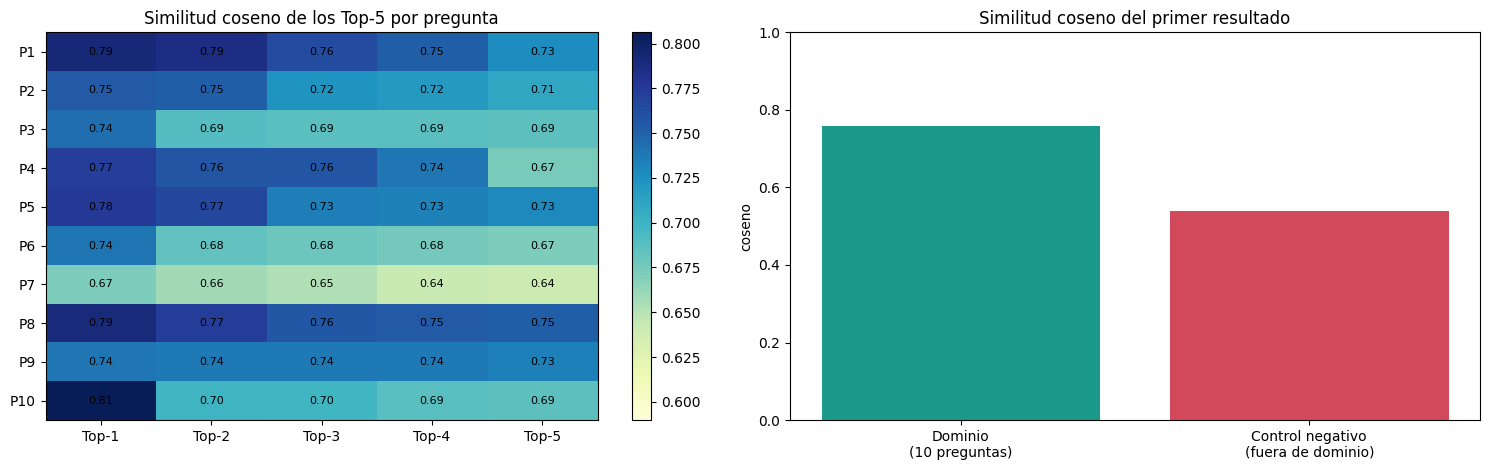

In [18]:
neg = [buscar(q, 5) for q in CONTROL_NEGATIVO]
neg_top1 = [r[0]["score"] for r in neg]
print("Control negativo (similitud coseno del primer resultado):")
for q, s in zip(CONTROL_NEGATIVO, neg_top1):
    print(f"  {s:.4f} · {q}")
print(f"\nSimilitud top-1 media en preguntas del dominio: {ev.score_top1.mean():.4f}")
print(f"Similitud top-1 media en control negativo:       {np.mean(neg_top1):.4f}")
print(f"Separación (dominio − fuera de dominio):          {ev.score_top1.mean() - np.mean(neg_top1):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
mat = np.array([s for s in ev.scores])
im = ax[0].imshow(mat, cmap="YlGnBu", aspect="auto", vmin=max(0, mat.min() - 0.05), vmax=mat.max())
ax[0].set_xticks(range(5), [f"Top-{i}" for i in range(1, 6)]); ax[0].set_yticks(range(len(ev)), [f"P{i+1}" for i in range(len(ev))])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax[0].text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Similitud coseno de los Top-5 por pregunta"); plt.colorbar(im, ax=ax[0])
ax[1].bar(["Dominio\n(10 preguntas)", "Control negativo\n(fuera de dominio)"], [ev.score_top1.mean(), np.mean(neg_top1)], color=["#1b998b", "#d1495b"])
ax[1].set(title="Similitud coseno del primer resultado", ylabel="coseno"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

### Comparación opcional de tamaños de chunk con recuperación real
En esta parte se puede activar la opción EVALUAR_TAMANOS = True en la celda de parámetros para probar diferentes tamaños de fragmentos y comparar cómo funciona la recuperación de información en cada caso. Estas pruebas se realizan en una base de datos temporal en memoria, por lo que no modifican la información almacenada en Qdrant Cloud. Es importante tener en cuenta que este proceso consume créditos de la API utilizada para generar los embeddings.

In [19]:
if EVALUAR_TAMANOS:
    cache, filas = {}, []
    _embed_original = embed
    def embed_cache(textos, tipo, titulos=None, reintentos=6):
        faltan = [t for t in textos if (t, tipo) not in cache]
        if faltan:
            for t, v in zip(faltan, _embed_original(faltan, tipo)):
                cache[(t, tipo)] = v
        return [cache[(t, tipo)] for t in textos]
    embed = embed_cache
    try:
        for size in (500, 1000, 1500):
            cs = construir_chunks(paginas, fichas, size, int(size * 0.15))
            mem, nombre = QdrantClient(":memory:"), f"tmp_{size}"
            mem.create_collection(nombre, vectors_config=VectorParams(size=DIM, distance=Distance.COSINE))
            for i in range(0, len(cs), BATCH_SIZE):
                lote = cs[i:i + BATCH_SIZE]
                vs = embed([c["texto"] for c in lote], "documento")
                mem.upsert(nombre, [PointStruct(id=c["id"], vector=v.tolist(), payload={**c["payload"], "texto": c["texto"]}) for c, v in zip(lote, vs)])
            e = evaluar(lambda q, k: buscar(q, k, cliente=mem, coleccion=nombre))
            filas.append(dict(chunk_size=size, fragmentos=len(cs), Hit_1=e.hit1.mean(), Hit_3=e.hit3.mean(), MRR=e.rr.mean(), score_top1=e.score_top1.mean()))
    finally:
        embed = _embed_original
    display(pd.DataFrame(filas).round(4))
else:
    print("Comparación de tamaños omitida (EVALUAR_TAMANOS = False).")

Comparación de tamaños omitida (EVALUAR_TAMANOS = False).


## 6. Estado final del clúster

In [20]:
info = cliente_q.get_collection(COLLECTION)
por_fuente = pd.Series([p["fuente"] for p in [x.payload for x in cliente_q.scroll(COLLECTION, limit=1000, with_payload=["fuente"])[0]]]).value_counts()
print(f"Colección: {COLLECTION} · puntos: {info.points_count} · dimensión: {DIM} · distancia: coseno · estado: {info.status}")
display(por_fuente.rename("fragmentos").to_frame())

Colección: rag_cancer_mama · puntos: 157 · dimensión: 768 · distancia: coseno · estado: green


,fragmentos
03_Guia_clinica_cancer_mama_2020.pdf,67
01_GPC_pacientes_MinSalud_2013.pdf,51
02_OMS_cancer_de_mama.pdf,21
wdbc.data,12
wdbc.names,6


## 7. Análisis

Durante el desarrollo de este trabajo pude comprender cómo se pueden integrar herramientas en la nube para almacenar, organizar y consultar información de manera más eficiente. La implementación permitió trabajar con documentos relacionados con el cáncer de mama y datos del conjunto UCI Breast Cancer Wisconsin, utilizando Gemini para generar los embeddings y Qdrant Cloud para almacenar y recuperar la información.

Uno de los aspectos que más me llamó la atención fue entender cómo funciona la búsqueda vectorial, ya que permite encontrar información relacionada con una pregunta teniendo en cuenta su significado y no solamente las palabras utilizadas. También pude identificar que la fragmentación de los documentos y la organización de los datos son fundamentales para obtener mejores resultados en las consultas.

En cuanto a los resultados, se indexaron 157 fragmentos en Qdrant Cloud (documentos clínicos y fichas del dataset) y se evaluaron 10 preguntas en lenguaje natural. En todas, el primer fragmento recuperado fue relevante (Hit@1 = 100 % y MRR = 1,00), con una similitud coseno media de 0,758 en el primer resultado. Las preguntas ajenas al tema (control negativo) obtuvieron en promedio 0,540, una diferencia de 0,219 que permitiría definir un umbral de rechazo cercano a 0,6.

Es importante aclarar que la relevancia se midió con palabras clave y con solo 10 preguntas, por lo que el resultado es optimista. Además, observé que los PDF dejan encabezados repetidos dentro de los fragmentos y que las fichas del dataset se parecen mucho entre sí, lo que reduce la diferencia entre sus puntajes de similitud.

## Conclusiones

Este ejercicio me permitió fortalecer mis conocimientos sobre computación en la nube y conocer de manera práctica cómo funciona la recuperación de información mediante un sistema RAG.

Considero que herramientas como Gemini y Qdrant Cloud ofrecen posibilidades interesantes para desarrollar soluciones que faciliten el acceso a grandes cantidades de información. Finalmente, este trabajo representa una buena base para continuar explorando este tipo de tecnologías e implementar sistemas que no solamente recuperen información, sino que también puedan generar respuestas más completas y contextualizadas.

## Referencias
Google AI for Developers. (s. f.). *Embeddings*. Gemini API. https://ai.google.dev/gemini-api/docs/embeddings

Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401

Ministerio de Salud y Protección Social & Colciencias. (2013). *Guía de práctica clínica (GPC) para la detección temprana, tratamiento integral, seguimiento y rehabilitación del cáncer de mama: Versión para pacientes y cuidadores* (Guía No. GPC-2013-19). https://www.minsalud.gov.co/sites/rid/Lists/BibliotecaDigital/RIDE/INEC/IETS/GPC_Ptes_Mama-3.pdf

Organización Mundial de la Salud. (s. f.). *Cáncer de mama* [Nota descriptiva]. https://www.who.int/es/news-room/fact-sheets/detail/breast-cancer

Qdrant Solutions GmbH. (2024). *Qdrant documentation: Vector search engine & cloud database*. https://qdrant.tech/documentation/

Wolberg, W., Street, N., & Mangasarian, O. (1995). *UCI Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic